# House Price Prediction – Machine Learning

**Goal:** Train one strong baseline regression model, evaluate it, and save the complete preprocessing + model pipeline for later FastAPI deployment.

> **Dataset note:** `house_price_sample_dataset.csv` is a synthetic teaching dataset created for learning. It is not a real-estate market dataset, and predictions from it should not be used for buying, selling, or valuing real homes.

## Files
- `house_price_sample_dataset.csv` – sample data used in this notebook.
- `house_price_model.joblib` – saved trained pipeline created at the end.

Keep the CSV in the same folder as this notebook.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

## 2. Load the dataset

In [2]:
df = pd.read_csv("house_price_sample_dataset.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (1200, 8)


,area_sqft,bedrooms,bathrooms,property_age_years,location,property_type,parking,price_inr
0,767,2,1,12,Suburb,Independent_House,Yes,2260000
1,2822,5,3,26,Suburb,Apartment,Yes,8132000
2,2464,5,4,27,IT_Corridor,Independent_House,Yes,7306000
3,1817,1,1,37,Suburb,Apartment,Yes,4360000
4,1799,2,1,32,City_Center,Independent_House,Yes,4586000


## 3. Basic data understanding

In [3]:
display(df.info())
display(df.describe(include="all"))
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   area_sqft           1200 non-null   int64 
 1   bedrooms            1200 non-null   int64 
 2   bathrooms           1200 non-null   int64 
 3   property_age_years  1200 non-null   int64 
 4   location            1200 non-null   object
 5   property_type       1200 non-null   object
 6   parking             1200 non-null   object
 7   price_inr           1200 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 75.1+ KB


None

,area_sqft,bedrooms,bathrooms,property_age_years,location,property_type,parking,price_inr
count,1200.000000,1200.000000,1200.000000,1200.000000,1200,1200,1200,1.200000e+03
unique,NaN,NaN,NaN,NaN,4,3,2,NaN
top,NaN,NaN,NaN,NaN,Suburb,Apartment,Yes,NaN
freq,NaN,NaN,NaN,NaN,438,697,889,NaN
mean,2012.733333,3.608333,2.374167,19.309167,NaN,NaN,NaN,5.823169e+06
std,863.093511,1.649909,1.090179,11.895020,NaN,NaN,NaN,2.629791e+06
min,513.000000,1.000000,1.000000,0.000000,NaN,NaN,NaN,9.400000e+05
25%,1262.250000,2.000000,1.000000,9.000000,NaN,NaN,NaN,3.534750e+06
50%,2018.000000,4.000000,2.000000,19.000000,NaN,NaN,NaN,5.887500e+06
75%,2770.750000,5.000000,3.000000,29.000000,NaN,NaN,NaN,8.073250e+06


Missing values:
 area_sqft             0
bedrooms              0
bathrooms             0
property_age_years    0
location              0
property_type         0
parking               0
price_inr             0
dtype: int64
Duplicate rows: 0


## 4. Exploratory data analysis

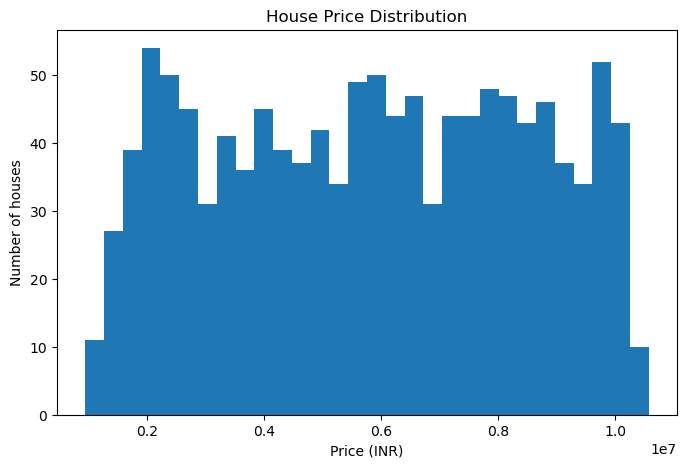

In [4]:
plt.figure(figsize=(8, 5))
plt.hist(df["price_inr"], bins=30)
plt.title("House Price Distribution")
plt.xlabel("Price (INR)")
plt.ylabel("Number of houses")
plt.show()

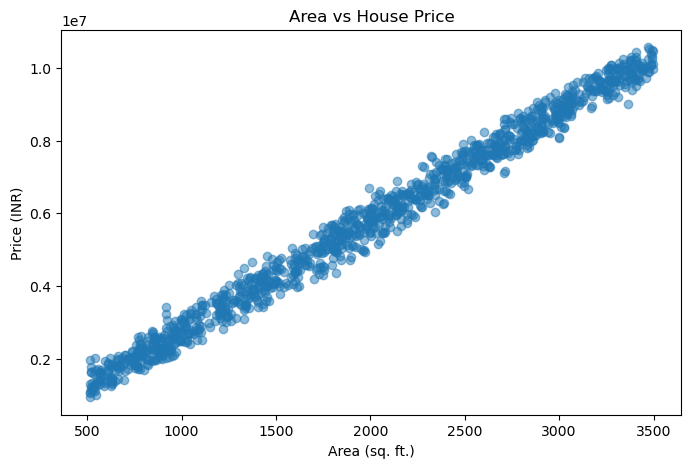

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df["area_sqft"], df["price_inr"], alpha=0.5)
plt.title("Area vs House Price")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price (INR)")
plt.show()

## 5. Separate features and target

- **Features (`X`)** are the information supplied about a house.
- **Target (`y`)** is the price that the model learns to predict.

In [6]:
X = df.drop(columns=["price_inr"])
y = df["price_inr"]

print("Feature columns:", X.columns.tolist())
print("Target:", y.name)

Feature columns: ['area_sqft', 'bedrooms', 'bathrooms', 'property_age_years', 'location', 'property_type', 'parking']
Target: price_inr


## 6. Split the data

We keep a test set separate so we can evaluate the model on rows it did not train on.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 960
Testing rows: 240


## 7. Build preprocessing and model pipeline

The numerical columns are imputed with their median. Categorical columns are imputed with the most frequent value and encoded using OneHotEncoder.

The preprocessing and Random Forest model are placed in **one Pipeline**. This is important for deployment: the same transformations are automatically applied to new inputs.

In [8]:
numeric_features = [
    "area_sqft", "bedrooms", "bathrooms", "property_age_years"
]
categorical_features = ["location", "property_type", "parking"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

house_price_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model)
])

## 8. Train the model

In [9]:
house_price_pipeline.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## 9. Evaluate the model

- **MAE:** Average absolute prediction error, in INR.
- **RMSE:** Penalizes larger errors more strongly, in INR.
- **R²:** Measures how much target variation is explained by the model. Values closer to 1 are generally better.

The results are only meaningful for this synthetic teaching dataset.

In [10]:
y_pred = house_price_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  ₹{mae:,.0f}")
print(f"RMSE: ₹{rmse:,.0f}")
print(f"R²:   {r2:.4f}")

MAE:  ₹99,319
RMSE: ₹130,762
R²:   0.9976


## 10. Compare actual and predicted prices

In [11]:
results = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})
display(results.head(10))

,Actual_Price,Predicted_Price
0,3568000,3.563917e+06
1,7301000,7.421177e+06
2,3171000,3.076137e+06
3,5058000,5.057203e+06
4,7895000,7.984100e+06
5,2007000,1.678435e+06
6,9939000,9.839747e+06
7,2303000,2.351534e+06
8,3495000,3.475722e+06
9,8792000,8.776128e+06


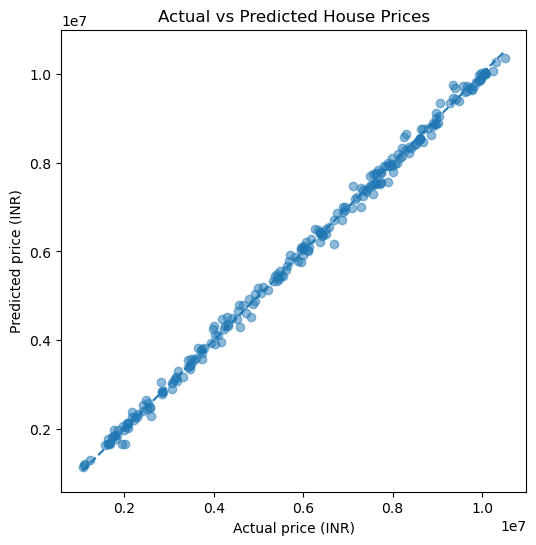

In [12]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual price (INR)")
plt.ylabel("Predicted price (INR)")
plt.title("Actual vs Predicted House Prices")
plt.show()

## 11. Save the complete trained pipeline

We save the complete pipeline, not just the Random Forest estimator. That means the encoders and imputers are saved together with the model.

Only load Joblib files that you created or trust. Loading an untrusted pickle/joblib file can execute malicious code.

In [13]:
model_path = "house_price_model.joblib"
joblib.dump(house_price_pipeline, model_path)
print(f"Saved model pipeline to: {model_path}")

Saved model pipeline to: house_price_model.joblib


## 12. Load the saved model and make a new prediction

In [14]:
loaded_model = joblib.load("house_price_model.joblib")

new_house = pd.DataFrame([{
    "area_sqft": 1500,
    "bedrooms": 3,
    "bathrooms": 2,
    "property_age_years": 5,
    "location": "Suburb",
    "property_type": "Apartment",
    "parking": "Yes"
}])

predicted_price = loaded_model.predict(new_house)[0]
print(f"Estimated sample prediction: ₹{predicted_price:,.0f}")

Estimated sample prediction: ₹4,509,962


## 13. Deployment handoff

For the next FastAPI lesson, the important artifacts are:

1. `house_price_model.joblib` – trained preprocessing + model pipeline.
2. The exact input feature names and data types shown in Section 12.
3. The package dependencies listed below.

A future FastAPI endpoint must send a DataFrame with the same feature names. Do not manually one-hot encode or scale the input again: the saved pipeline already does that.

### Suggested `requirements.txt`
```text
fastapi
uvicorn
pandas
numpy
scikit-learn
joblib
```

**Next step:** Build a FastAPI app that loads `house_price_model.joblib`, accepts the seven input fields, and returns the predicted price. Then test locally before deploying to Render.

In [15]:
import joblib

model = joblib.load("house_price_model.joblib")

print("Model loaded successfully!")

Model loaded successfully!
